# MJO convection-wind coupling

## Purpose

Diagnose how strongly and with what phase lag the low-level wind follows convection over the Indian Ocean-Maritime Continent in each experiment and in observations.

## Inputs

Model: the 2012-2013 AMIP hindcasts under `INPUT_DATA_ROOT/<case>/post/atm/180x360_aave` (experiments and initial states in `configs/hind_experiment_config.py`). Daily FLUT and U850. Observations: NOAA OLR and ERA5 daily U850.

## Method

OLR and U850 anomalies (seasonal cycle as in notebook 01) averaged over 10S-10N, 60-150E, band-passed to 20-100 days (FFT) and standardized; lag correlation corr(OLR(t), U850(t + lag)), positive lag = U850 lags OLR. An MJO-like coupling gives a negative minimum at a positive lag (westerlies following convection). No sign alignment with the reference is applied.

## Outputs

`data/hind_atm_mjo/mjo/mjo_coupling_OLR_U850_<SOURCE>_<period>.nc`, `mjo_coupling_summary.csv`, `figure/hind_atm_mjo/mjo/`.

## 1. Libraries

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
from IPython.display import display

## 2. User setup

Paths and run options. Edit this cell for normal changes; it holds plain values only, so `papermill -p` overrides work.

In [2]:
INPUT_DATA_ROOT = Path("/global/cfs/cdirs/m4849/zhan391/eam_hindcast")
WORK_DIR = Path("/global/cfs/cdirs/m4849/zhan391/work_package/e3sm_dart_analysis")
DIAGNOSTIC_OUTPUT_ROOT = Path("/global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026")
OBSERVATION_ROOT = Path("/global/cfs/cdirs/e3sm/zhan391/data")  # reference-data archive
WORKFLOW_NAME = "hind_atm_mjo"

EXPERIMENTS = ("CTRL", "DARTOP", "ERA5OP", "ERA5DL", "ERA5BL", "DARTBL", "DARTBA", "DARTAE")
LAT_BAND = (-10.0, 10.0)
LON_SECTOR = (60.0, 150.0)
BANDPASS_DAYS = (20.0, 100.0)
SEASONAL_CYCLE = "harmonics"
FORCE_COMPUTE = False
SHOW = True
FIGURE_DPI = 300
USE_DISTRIBUTED = False  # True: local dask.distributed cluster; worker processes read files in parallel
DASK_WORKERS = 8         # threads (threaded scheduler) or worker processes (distributed); bounds memory

## 3. Paths and modules

In [3]:
repo = WORK_DIR.resolve()
if str(repo / "diagnostic") not in sys.path:
    sys.path.insert(0, str(repo / "diagnostic"))
from configs.output_paths import workflow_output_dirs
from util.dask_helpers import compute_all, configure_dask

client = configure_dask(use_distributed=USE_DISTRIBUTED, n_workers=DASK_WORKERS, n_threads=DASK_WORKERS)
data_dir, figure_dir = workflow_output_dirs(WORKFLOW_NAME, 'mjo', output_root=DIAGNOSTIC_OUTPUT_ROOT)
ROOTS = dict(observation_root=OBSERVATION_ROOT)
print(f"[DATA] {data_dir}\n[FIGURE] {figure_dir}")

def save(fig, name):
    path = figure_dir / name
    fig.savefig(path, dpi=FIGURE_DPI, bbox_inches="tight")
    print(f"[FIGURE] {path}")
    if not SHOW:
        plt.close(fig)

[DATA] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_atm_mjo/mjo
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_mjo/mjo


## 4. Read input

Saved diagnostics are reused: fields are opened lazily only for the sources whose output file is missing (all of them with `FORCE_COMPUTE`), and loaded in the Derive step.

In [4]:
from util.mjo_hovmoller_coupling import coupling_path, open_mjo_input

SOURCES = ("OBS", *EXPERIMENTS)
lat_range = (min(LAT_BAND) - 5, max(LAT_BAND) + 5)
paths = {s: coupling_path(data_dir, s) for s in SOURCES}
inputs = {s: {v: open_mjo_input(s, v, data_root=INPUT_DATA_ROOT, lat_range=lat_range, **ROOTS)
              for v in ("FLUT", "U850")}
          for s in SOURCES if FORCE_COMPUTE or not paths[s].exists()}
print(f"[READ] {', '.join(inputs) or 'nothing: every coupling curve is saved'}")

[READ] nothing: every coupling curve is saved


## 5. Derive

Band-passed sector-mean series and their lag correlation per source. The expensive reductions of every source are computed together in one Dask graph (`compute_all`), so reads and reductions run in parallel; the rest works on the loaded results.

In [5]:
from util.mjo_hovmoller_coupling import MjoConfig, MjoDiagnostics

cfg = MjoConfig(lat_band=LAT_BAND, coupling_lon_sector=LON_SECTOR, bandpass_days=BANDPASS_DAYS,
                seasonal_cycle=SEASONAL_CYCLE)
diag = MjoDiagnostics(cfg)
series = compute_all({(s, v): diag.sector_reduce(da) for s, f in inputs.items() for v, da in f.items()})
derived = {s: diag.lag_correlation(diag.sector_finish(series[s, "FLUT"]), diag.sector_finish(series[s, "U850"]))
           for s in inputs}

## 6. Save

Write the newly derived files, then reload every source from disk so the steps below use the same data as a rerun that reuses the files.

In [6]:
from util.mjo_hovmoller_coupling import load_coupling

for s, curve in derived.items():
    curve.to_dataset().assign_attrs(source=s, lon_sector=str(cfg.coupling_lon_sector),
                                    bandpass_days=str(cfg.bandpass_days), lag_sign="positive lag: U850 lags OLR",
                                    lat_band=str(cfg.lat_band), seasonal_cycle=cfg.seasonal_cycle,
                                    n_harmonics=cfg.n_harmonics).to_netcdf(paths[s])
    print(f"[WRITE] {paths[s]}")
curves = load_coupling(data_dir, SOURCES)

## 7. Scores

Minimum correlation, its lag, and the lag-0 correlation.

In [7]:
from util.mjo_hovmoller_coupling import coupling_summary

summary = coupling_summary(curves)
summary.to_csv(data_dir / "mjo_coupling_summary.csv")
print(f"[WRITE] {data_dir / 'mjo_coupling_summary.csv'}")
display(summary.round(2))

[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_atm_mjo/mjo/mjo_coupling_summary.csv


,min_corr,lag_at_min,corr_lag0
source,,,
OBS,-0.57,9,-0.09
CTRL,-0.70,8,-0.21
DARTOP,-0.61,7,-0.22
ERA5OP,-0.49,7,-0.18
ERA5DL,-0.73,7,-0.26
ERA5BL,-0.68,8,-0.22
DARTBL,-0.58,6,-0.26
DARTBA,-0.61,5,-0.37
DARTAE,-0.65,8,-0.21


## 8. Plot and show

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_mjo/mjo/mjo_coupling_OLR_U850.png


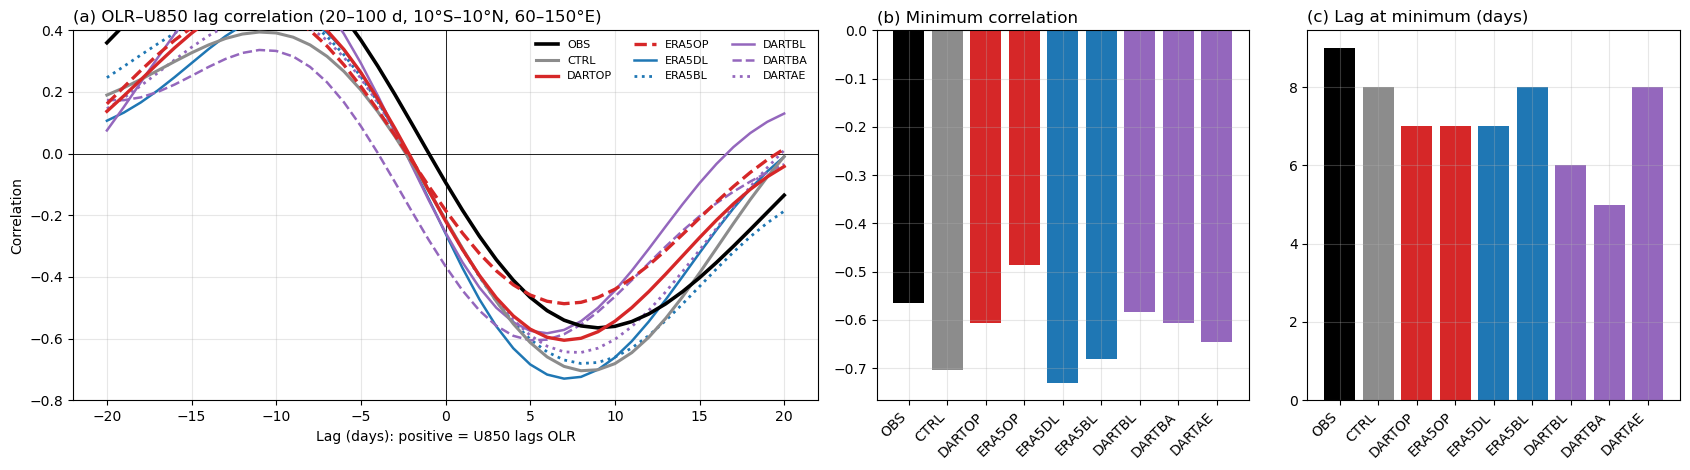

In [8]:
from util.mjo_hovmoller_coupling import plot_coupling

save(plot_coupling(curves), "mjo_coupling_OLR_U850.png")